In [31]:
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

np.random.seed(2025)

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.patches as patches

from src.SHRED import SHRED, fit, predict
from src.processdata import TimeSeriesDataset, Padding
from src.utils import dim_reduction, num2p, mre, mse, mae, rmse

## **Double gyre flow**

The double gyre flow is a time-dependent model for two counter-rotating vortices (gyres) in a rectangular domain. When time is introduced via a periodic perturbation, the central dividing line between the two gyres oscillates left and right, creating a time-varying velocity field that can lead to chaotic particle trajectories. The velocity field $\mathbf{v} = [u, v]^T$ in the domain $[0, L_x] \times [0, L_y]$ and in the time interval $[0, T]$ is given by

$$
\begin{align}
u(x, y, t) &= -\pi I \sin\left( \pi f(x, t) \right) \cos\left( \pi y \right)
\\
v(x, y, t) &= \pi I \cos\left( \pi f(x, t) \right) \sin\left( \pi y \right) \frac{\partial f}{\partial x}
\end{align}
$$

\
where $I$ is the intensity parameter, $f(x, t) = \epsilon \sin(\omega t) x^2 + (1 - 2\epsilon \sin(\omega t)) x $, $\epsilon$ and $\omega$ are the perturbation amplitude and the frequency of the oscillation, respectively.

## Solver

In [32]:
# DEFINE THE SYSTEM SOLVER

def double_gyre_flow(amplitude, frequency, x, y, t):
    '''
    Solve the double gyre flow problem

    Inputs
        amplitude                   (`float`)
        frequency                   (`float`)
        horizontal discretization   (`np.array[float]`, shape: (ny,))
        vertical discretization     (`np.array[float]`, shape: (nx,))
        time vector                 (`np.array[float]`, shape: (ntimes,))

    Output
        horizontal velocity matrix  (`np.array[float]`, shape: (ntimes, nx * ny)
        vertical velocity matrix    (`np.array[float]`, shape: (ntimes, nx * ny)
    '''

    xgrid, ygrid = np.meshgrid(x, y)         # spatial grid

    u = np.zeros((len(t), len(x), len(y)))   # horizontal velocity
    v = np.zeros((len(t), len(x), len(y)))   # vertical velocity

    intensity = 0.1   # intensity parameter

    f = lambda x,t: amplitude * np.sin(frequency * t) * x**2 + x - 2 * amplitude * np.sin(frequency * t) * x

    # compute solution
    for i in range(len(t)):
      u[i] = (-np.pi * intensity * np.sin(np.pi * f(xgrid, t[i])) * np.cos(np.pi * ygrid)).T
      v[i] = (np.pi * intensity * np.cos(np.pi * f(xgrid, t[i])) * np.sin(np.pi * ygrid) * (2 * amplitude * np.sin(frequency * t[i]) * xgrid + 1.0 - 2 * amplitude * np.sin(frequency * t[i]))).T

    return u, v

In [33]:
# SOLVE THE SYSTEM FOR A FIXED TRANSPORT TERM

amplitude = 0.25    # amplitude
frequency = 5.0     # frequency

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

u, v = double_gyre_flow(amplitude, frequency, x, y, t)

In [34]:
# SOLUTION VISUALIZATION

def vorticity(u, v):
    dx = Lx / nx
    dy = Ly / ny
    du_dy = np.gradient(u, dy, axis = 1)
    dv_dx = np.gradient(v, dx, axis = 0)
    return dv_dx - du_dy

def plot_solution(time):

    which_time = (np.abs(t - time)).argmin()
    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(u[which_time], v[which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, u[which_time].T, v[which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Solution at time t = {round(time, 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))


interact(plot_solution, time = FloatSlider(value = t[0], min = t[0], max = t[-1], step = (t[1]-t[0]), description='time', layout={'width': '400px', 'height': '50px'}));

interactive(children=(FloatSlider(value=0.0, description='time', layout=Layout(height='50px', width='400px'), …

In [35]:
# DATA GENERATION

amplitude_range = np.array([0.0, 0.5])
frequency_range = np.array([0.5, 2*np.pi])

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

# training data generation
ntrajectories = 100
U = np.zeros((ntrajectories, ntimes, nx, ny))
V = np.zeros((ntrajectories, ntimes, nx, ny))

for i in range(ntrajectories):
  amplitude = (amplitude_range[1] - amplitude_range[0]) * np.random.rand() + amplitude_range[0]
  frequency = (frequency_range[1] - frequency_range[0]) * np.random.rand() + frequency_range[0]
  U[i], V[i] = double_gyre_flow(amplitude, frequency, x, y, t)

In [36]:
# DATA VISUALIZATION

def plot_data(which_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(U[which_trajectory, which_time], V[which_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, U[which_trajectory, which_time].T, V[which_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Trajectory {which_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))

interact(plot_data, which_trajectory = IntSlider(min = 0, max = ntrajectories - 1, step = 1, description='Trajectory'), which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step'));

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), IntSlider(value=0, description='Ti…

## PreProcessing

In [37]:
# TORCH CONVERSION

U = torch.from_numpy(U.reshape(ntrajectories, ntimes, nstate))
V = torch.from_numpy(V.reshape(ntrajectories, ntimes, nstate))

In [38]:
# TRAIN-VALIDATION SPLITTING

split_ratio = 0.8

ntrain = round(split_ratio * ntrajectories)

idx_train = np.random.choice(ntrajectories, size = ntrain, replace = False)
mask = np.ones(ntrajectories)
mask[idx_train] = 0
idx_valid_test = np.arange(0, ntrajectories)[np.where(mask!=0)[0]]
idx_valid = idx_valid_test[::2]
idx_test = idx_valid_test[1::2]

nvalid = idx_valid.shape[0]
ntest = idx_test.shape[0]

Utrain = U[idx_train]
Uvalid = U[idx_valid]
Utest = U[idx_test]

Vtrain = V[idx_train]
Vvalid = V[idx_valid]
Vtest = V[idx_test]

## POD based reduction

In [39]:
POD_modes = 4

Residual energy is equal to  6.189785026138125e-07



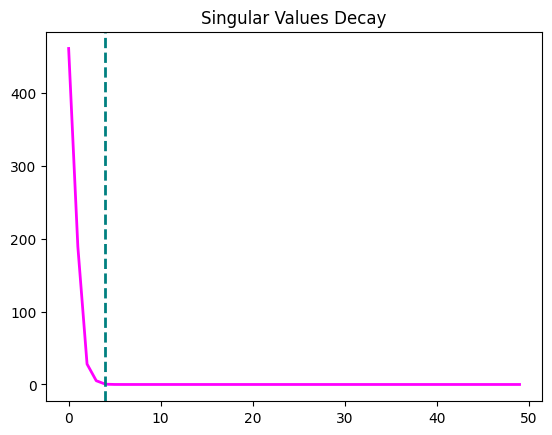

In [40]:
# DIMENSIONALITY REDUCTION - HORIZONTAL VELOCITY

Utrain, Uvalid, Utest, Utrain_proj, Uvalid_proj, Utest_proj, V1_POD = dim_reduction(Utrain, Uvalid, Utest, POD_modes)

Residual energy is equal to  5.280659835332175e-06



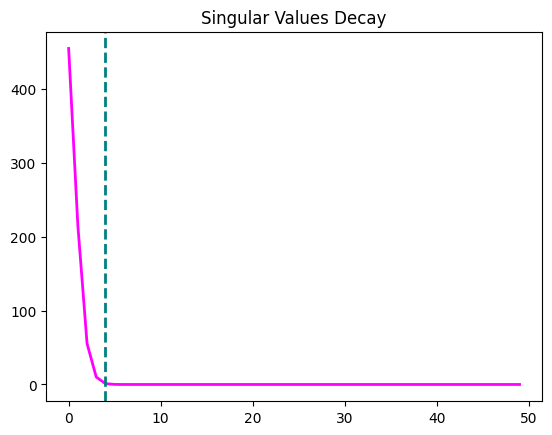

In [41]:
# DIMENSIONALITY REDUCTION - VERTICAL VELOCITY

Vtrain, Vvalid, Vtest, Vtrain_proj, Vvalid_proj, Vtest_proj, V2_POD = dim_reduction(Vtrain, Vvalid, Vtest, POD_modes)

## Broken sensors simulations

In [42]:
# EXTRACT SENSORS DATA

nsensors = 3
short_broken = 1
long_broken = 1 

idx_sensors = np.random.choice(nstate, size = nsensors, replace = False)
idx_short_broken_s = idx_sensors[0:short_broken]
idx_long_broken_s = idx_sensors[short_broken:short_broken+long_broken]

print("Available sensors:\t", idx_sensors)
print("short broken sensors:\t", idx_short_broken_s)
print("long broken sensors:\t", idx_long_broken_s)

sensors_data_train = Utrain[:,:,idx_sensors]
sensors_data_valid = Uvalid[:,:,idx_sensors]
sensors_data_test = Utest[:,:,idx_sensors]

idx_sensors_x, idx_sensors_y = np.unravel_index(idx_sensors, (nx, ny))
sensors_coordinates = np.vstack((x[idx_sensors_x], y[idx_sensors_y]))

Available sensors:	 [899 366 839]
short broken sensors:	 [899]
long broken sensors:	 [366]


In [43]:
# SHORT BROKEN SIMULATION

# broken = bernoulli distribution
p_short_broken = 0.2
for idx in idx_short_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    mask_train = torch.rand(sensors_data_train[:, :, local_idx].shape) < p_short_broken
    mask_valid = torch.rand(sensors_data_valid[:, :, local_idx].shape) < p_short_broken
    mask_test = torch.rand(sensors_data_test[:, :, local_idx].shape) < p_short_broken

    print("simulation of short broken sensor idx\t", idx, "\twith probability", p_short_broken)

    sensors_data_train[:, :, local_idx][mask_train] = float('nan')
    sensors_data_valid[:, :, local_idx][mask_valid] = float('nan')
    sensors_data_test[:, :, local_idx][mask_test] = float('nan')


# LONG BROKEN SIMULATION

#draw 2 numbers and erase in the middle
for idx in idx_long_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30: # if the interval is too short, make it longer
        t_end = min(t_start + 38, ntimes-1)
    print("simulation of long broken sensor idx\t", idx, "\tfrom time step", t_start, "to time step", t_end)

    sensors_data_train[:, t_start:t_end + 1, local_idx] = float('nan')
    sensors_data_valid[:, t_start:t_end + 1, local_idx] = float('nan')
    sensors_data_test[:, t_start:t_end + 1, local_idx] = float('nan')

simulation of short broken sensor idx	 899 	with probability 0.2
simulation of long broken sensor idx	 366 	from time step 36 to time step 80


In [44]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, trajectory=0, sensor_labels=None):
    traj_idx = min(trajectory, sensor_data.shape[0] - 1)
    availability = (~torch.isnan(sensor_data[traj_idx])).to(torch.float32).cpu().numpy()
    time = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    if sensor_labels.shape[0] != nsensors_plot:
        raise ValueError("sensor_labels length must match number of sensor columns")

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")

    plt.title(f"{title_prefix} - Trajectory {traj_idx}")
    plt.tight_layout()
    plt.show()

In [45]:
def plot_train_data_availability(trajectory=0):
    plot_data_availability(
        sensors_data_train,
        "Train availability",
        trajectory,
        sensor_labels=np.arange(sensors_data_train.shape[2])
    )

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

## **Idea 0:** remove sensors


In [46]:
ERRORS = []

In [47]:
## REMOVE SENSORS NOT ALWAYS AVAILABLE

# Keep only sensors that are always available in all splits.
always_available_mask = (
    (~torch.isnan(sensors_data_train)).all(dim=(0, 1))
    & (~torch.isnan(sensors_data_valid)).all(dim=(0, 1))
    & (~torch.isnan(sensors_data_test)).all(dim=(0, 1))
)
keep_sensor_idx = np.where(always_available_mask.cpu().numpy())[0]

cleaned_sensors_data_train = sensors_data_train[:, :, keep_sensor_idx]
cleaned_sensors_data_valid = sensors_data_valid[:, :, keep_sensor_idx]
cleaned_sensors_data_test = sensors_data_test[:, :, keep_sensor_idx]

removed_sensor_idx = np.setdiff1d(np.arange(nsensors), keep_sensor_idx)
print("Kept local sensor columns:\t", keep_sensor_idx)
print("Removed local sensor columns:\t", removed_sensor_idx)
navailable_sensors = len(keep_sensor_idx)
print("Number of available sensors after cleaning:\t", navailable_sensors)

# PLOT CLEANED DATA AVAILABILITY (TRAIN ONLY)
def plot_cleaned_train_data_availability(trajectory=0):
    plot_data_availability(
        cleaned_sensors_data_train,
        "Cleaned Train availability",
        trajectory,
        sensor_labels=keep_sensor_idx
    )

interact(
    plot_cleaned_train_data_availability,
    trajectory=IntSlider(min=0, max=cleaned_sensors_data_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

Kept local sensor columns:	 [2]
Removed local sensor columns:	 [0 1]
Number of available sensors after cleaning:	 1


interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

In [48]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(cleaned_sensors_data_train, lag).to(device)
valid_data_in = Padding(cleaned_sensors_data_valid, lag).to(device)
test_data_in = Padding(cleaned_sensors_data_test, lag).to(device)

train_data_out = Padding(torch.cat((Utrain_proj, Vtrain_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((Uvalid_proj, Vvalid_proj), 2), 1).squeeze(1).to(device)
test_data_out = Padding(torch.cat((Utest_proj, Vtest_proj), 2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")

Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 1]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])


In [49]:
# SHRED TRAINING

shred = SHRED(
    navailable_sensors, 2*POD_modes, hidden_size = 64, hidden_layers = 2, decoder_sizes = [], dropout = 0.1
).to(device)
train_errors, valid_errors = fit(
    shred, train_dataset, valid_dataset, batch_size = 64, epochs = 200, lr = 1e-3, verbose = True, patience = 40
)

Training: 100%|██████████| 200/200 [02:23<00:00,  1.40it/s, Train Error=3.61%, Val Error=3.91%, Patience=12] 

Training Complete (200 epochs)


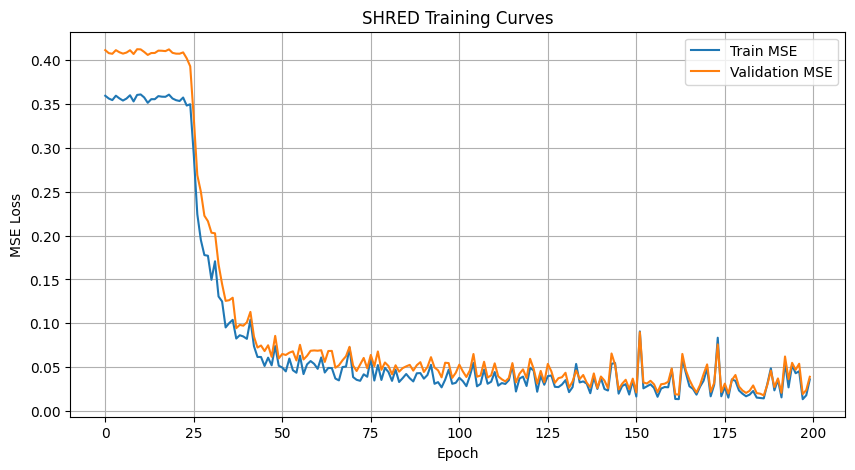

In [50]:
# PLOT TRAINING CURVES

plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('SHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

In [51]:
shred.freeze()

UVtest_hat = shred(test_data_in).cpu().to(torch.float64)

Utest_hat = UVtest_hat[:,:POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(ntest, ntimes, nx, ny)
Utest = Utest.reshape(ntest, ntimes, nx, ny)

Vtest_hat = UVtest_hat[:,POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(ntest, ntimes, nx, ny)
Vtest = Vtest.reshape(ntest, ntimes, nx, ny)

available_local_idx = keep_sensor_idx if 'keep_sensor_idx' in globals() else np.arange(nsensors)
unavailable_local_idx = np.setdiff1d(np.arange(nsensors), available_local_idx)

def plot_shred_reconstruction(which_test_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (20,5))
    plt.subplot(1, 2, 1)
    plt.contourf(x, y, vorticity(Utest[which_test_trajectory, which_time],  Vtest[which_test_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, Utest[which_test_trajectory, which_time].T, Vtest[which_test_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Test case {which_test_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))
    for idx, k in enumerate(available_local_idx):
      plt.plot(
          sensors_coordinates[0, k], sensors_coordinates[1, k],
          'o', mfc = 'magenta', mec = 'black', ms = 12, mew = 2.0,
          label='Available sensor' if idx == 0 else None
      )
    for idx, k in enumerate(unavailable_local_idx):
      plt.plot(
          sensors_coordinates[0, k], sensors_coordinates[1, k],
          'x', color='red', ms = 14, mew = 3.0,
          label='Unavailable sensor' if idx == 0 else None
      )
    plt.legend(loc='upper right', frameon=True)

    plt.subplot(1, 2, 2)
    plt.contourf(x, y, vorticity(Utest_hat[which_test_trajectory, which_time],  Vtest_hat[which_test_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, Utest_hat[which_test_trajectory, which_time].T, Vtest_hat[which_test_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'SHRED reconstruction at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))
    for idx, k in enumerate(available_local_idx):
      plt.plot(
          sensors_coordinates[0, k], sensors_coordinates[1, k],
          'o', mfc = 'magenta', mec = 'black', ms = 12, mew = 2.0,
          label='Available sensor' if idx == 0 else None
      )
    for idx, k in enumerate(unavailable_local_idx):
      plt.plot(
          sensors_coordinates[0, k], sensors_coordinates[1, k],
          'x', color='red', ms = 14, mew = 3.0,
          label='Unavailable sensor' if idx == 0 else None
      )
    plt.legend(loc='upper right', frameon=True)

interact(plot_shred_reconstruction, which_test_trajectory = IntSlider(value = 0, min = 0, max = ntest - 1, description='Test case'), which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step'));

interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…

In [52]:
## COMPUTE THE TEST ERROR

# Reshape for error computation
Utest_flat = Utest.reshape(ntest * ntimes, -1)
Vtest_flat = Vtest.reshape(ntest * ntimes, -1)
Utest_hat_flat = Utest_hat.reshape(ntest * ntimes, -1)
Vtest_hat_flat = Vtest_hat.reshape(ntest * ntimes, -1)

# Compute errors for U component
U_mse = mse(Utest_flat, Utest_hat_flat)
U_rmse = rmse(Utest_flat, Utest_hat_flat)
U_mae = mae(Utest_flat, Utest_hat_flat)
U_mre = mre(Utest_flat, Utest_hat_flat)


# Compute errors for V component
V_mse =  mse(Vtest_flat, Vtest_hat_flat)
V_rmse = rmse(Vtest_flat, Vtest_hat_flat)
V_mae = mae(Vtest_flat, Vtest_hat_flat)
V_mre = mre(Vtest_flat, Vtest_hat_flat)

# Combined error
combined_mse = (U_mse + V_mse) / 2
combined_rmse = (U_rmse + V_rmse) / 2
combined_mae = (U_mae + V_mae) / 2
combined_mre = (U_mre + V_mre) / 2

# Store results
test_error = {
    'model': 'Only always available sensors',
    'val-mre': num2p(valid_errors[-1]),
    'test-mre': num2p(combined_mre),
    'test-rmse': num2p(combined_rmse),
}

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)


                           model val-mre test-mre test-rmse
0  Only always available sensors   3.91%    3.80%    34.97%
